# Training-only exploratory analysis

This executed notebook describes the frozen training partition. The held-out set is not used for feature discovery. Source quality is documented by the unchanged original audit and cleaning log. Core feature choices and the bounded experiment protocol were specified before the final evaluation; this notebook adds descriptive evidence, not post-test model revisions.

Questions: how imbalanced are the labels, which metadata associations are visible, and what information is missing? Figures are descriptive associations, not causal explanations.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from netflix_ml.shared.io import root
from netflix_ml.tasks.task_03.data import LABELS
from netflix_ml.tasks.task_03.features import tokens

all_rows = pd.read_csv(root() / 'data/processed/task-03/cleaned.csv')
train = all_rows.loc[all_rows['split'] == 'train'].copy()
print('Training rows:', len(train))
print('Target distribution:')
print(train['rating'].value_counts().reindex(LABELS).to_string())


Training rows: 7029
Target distribution:
rating
G             33
NC-17          2
NR            63
PG           230
PG-13        392
R            638
TV-14       1724
TV-G         176
TV-MA       2564
TV-PG        689
TV-Y         245
TV-Y7        266
TV-Y7-FV       5
UR             2


The majority label is TV-MA. Accuracy alone is insufficient; macro-F1 gives every original label equal weight. NC-17 and UR have only two training examples, constraining CV to two folds.

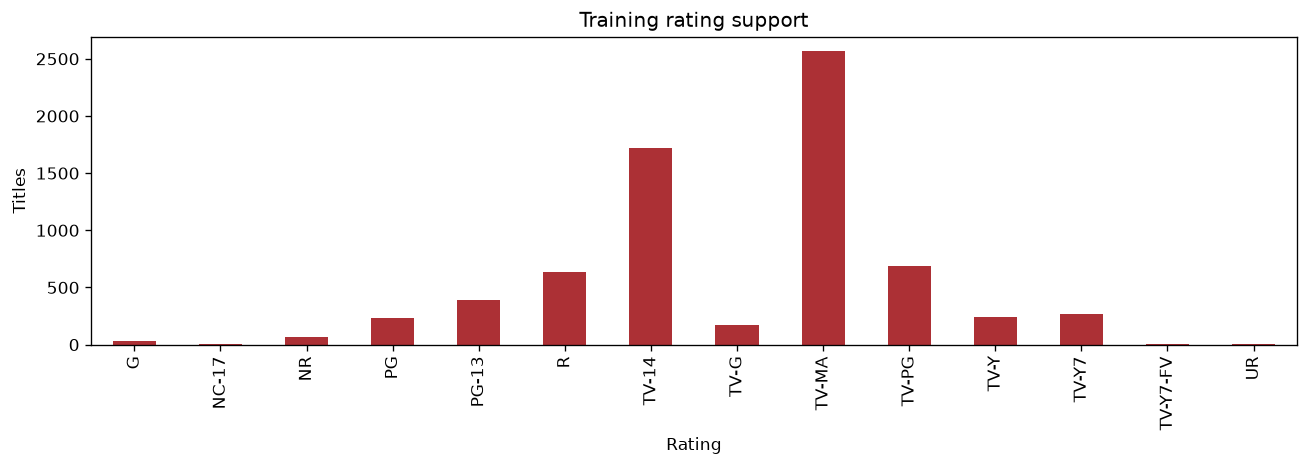

In [2]:
fig, ax = plt.subplots(figsize=(11,4))
train['rating'].value_counts().reindex(LABELS).plot.bar(ax=ax, color='#ac3035')
ax.set(title='Training rating support', xlabel='Rating', ylabel='Titles')
fig.tight_layout()


Type by rating:
type      Movie  TV Show
rating                  
G            33        0
NC-17         2        0
NR           60        3
PG          230        0
PG-13       392        0
R           637        1
TV-14      1148      576
TV-G         99       77
TV-MA      1648      916
TV-PG       428      261
TV-Y        100      145
TV-Y7       110      156
TV-Y7-FV      4        1
UR            2        0


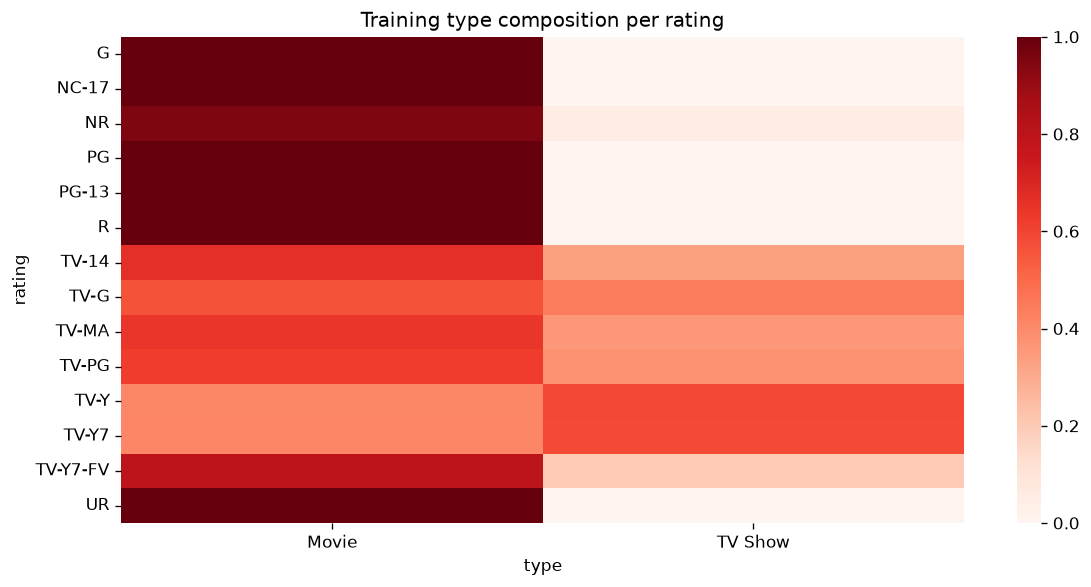

In [3]:
print('Type by rating:')
print(pd.crosstab(train['rating'], train['type']).to_string())
fig, ax = plt.subplots(figsize=(10,5))
sns.heatmap(pd.crosstab(train['rating'],train['type'],normalize='index'),cmap='Reds',ax=ax,vmin=0,vmax=1)
ax.set_title('Training type composition per rating')
fig.tight_layout()


Type distinguishes film/TV rating conventions, but metadata alone does not provide content-review evidence. Keep original labels separate and evaluate within each type with explicit label scope.

Distinct observed genre tokens: 42


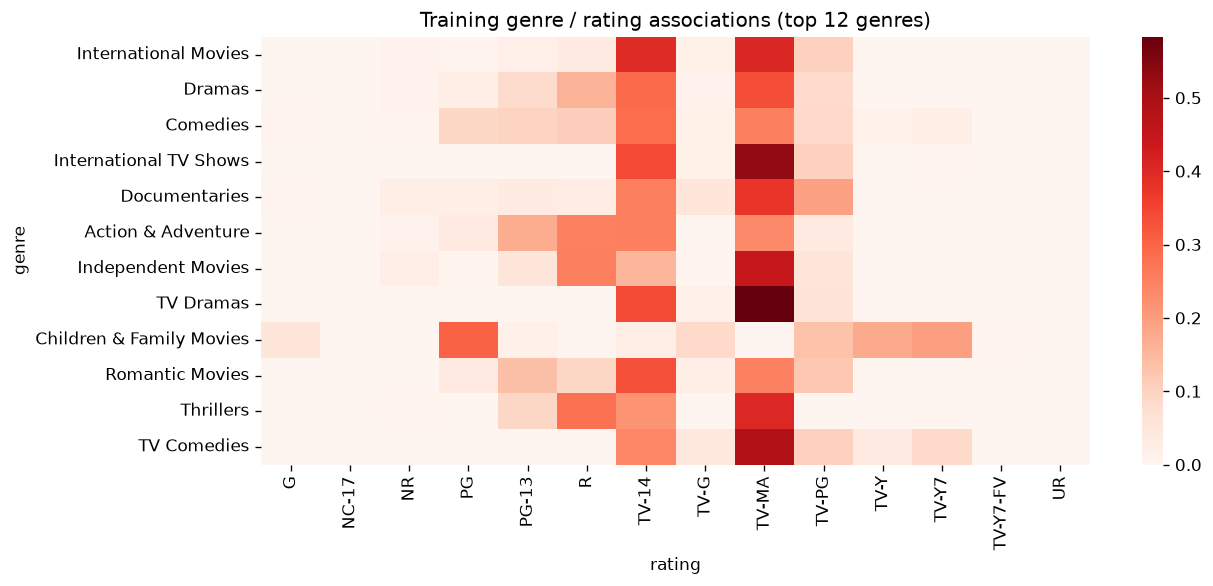

In [4]:
genres = train.assign(genre=train['listed_in'].map(tokens)).explode('genre')
top = genres['genre'].value_counts().head(12).index
fig, ax = plt.subplots(figsize=(11,5))
sns.heatmap(pd.crosstab(genres['genre'],genres['rating'],normalize='index').reindex(top), cmap='Reds',ax=ax)
ax.set_title('Training genre / rating associations (top 12 genres)')
fig.tight_layout()
print('Distinct observed genre tokens:', genres['genre'].nunique())


Semantic missing values in training:
country 237
director 2074


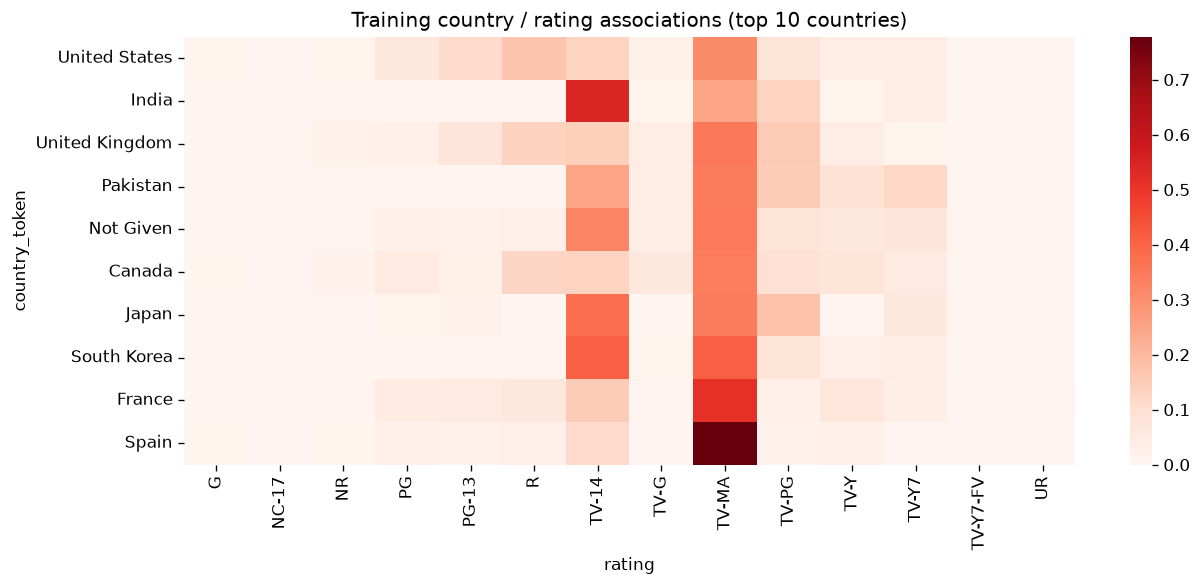

In [5]:
countries = train.assign(country_token=train['country'].map(tokens)).explode('country_token')
top_countries = countries['country_token'].value_counts().head(10).index
fig, ax = plt.subplots(figsize=(11,5))
sns.heatmap(pd.crosstab(countries['country_token'],countries['rating'],normalize='index').reindex(top_countries),cmap='Reds',ax=ax)
ax.set_title('Training country / rating associations (top 10 countries)')
fig.tight_layout()
print('Semantic missing values in training:')
for col in ['country','director']:
    print(col, int(train[col].eq('Not Given').sum()))


Genre and country indicators describe catalog associations and may reflect rating-system or sampling differences. Missing director metadata motivates an explicit ablation rather than assuming it improves the model. Dictionaries are fitted inside each CV training fold, never from the holdout.

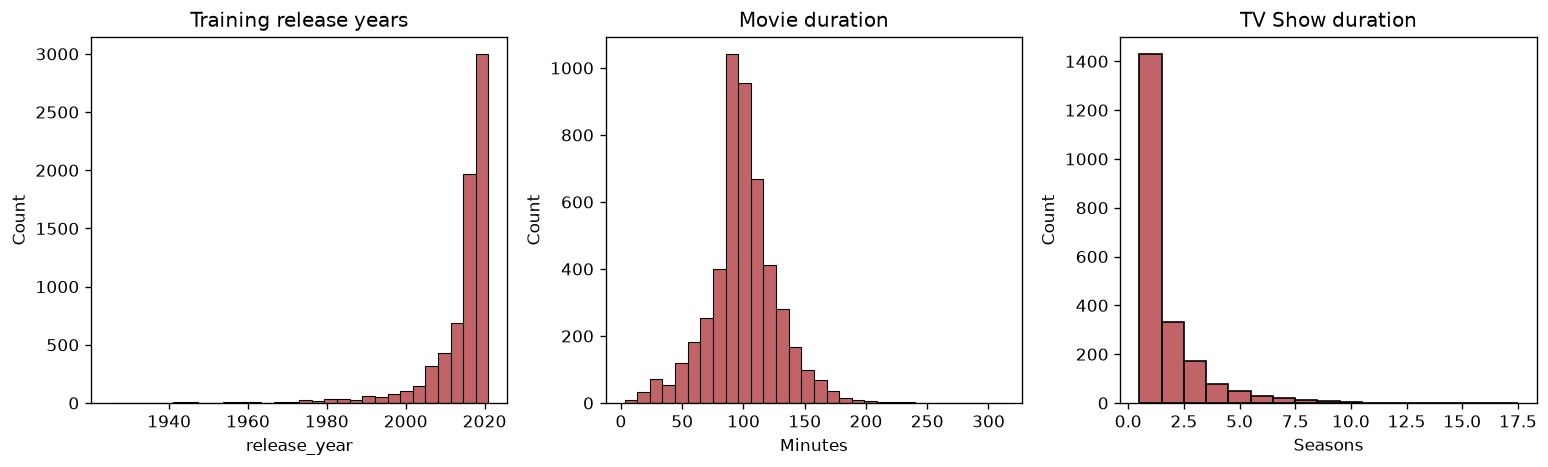

In [6]:
train['duration_value'] = train['duration'].str.extract(r'^(\d+)')[0].astype(int)
fig, axes = plt.subplots(1,3,figsize=(13,4))
sns.histplot(train['release_year'],ax=axes[0],color='#ac3035',bins=30)
axes[0].set_title('Training release years')
sns.histplot(train.loc[train['type']=='Movie','duration_value'],ax=axes[1],color='#ac3035',bins=30)
axes[1].set(title='Movie duration',xlabel='Minutes')
sns.histplot(train.loc[train['type']=='TV Show','duration_value'],ax=axes[2],color='#ac3035',discrete=True)
axes[2].set(title='TV Show duration',xlabel='Seasons')
fig.tight_layout()


Duration cannot be treated as a shared physical quantity: minutes and season counts are encoded separately with content type. Historical year coverage limits extrapolation. Date-added anomalies and four repeated entities are reviewed in the cleaning log; entity grouping prevents fit/validation overlap. No label merging, source-title guessing or test-driven revisions are performed.